# 0. Initialization / requirements

In [1]:
!pip install pandas

import random
from dataclasses import dataclass

import pandas as pd

# Part 1) Rebuilding the Data Model

In [2]:
@dataclass(slots=True)
class Song:
    title: str
    artist: str
    genre: str
    duration_sec: int

    def summary(self) -> str:
        return f"{self.title} by {self.artist} ({self.genre}, {self.duration_sec // 60}:{self.duration_sec % 60:02})"




@dataclass(slots=True)
class Listener:
    _listener_id: str
    name: str
    home_city: str

    def get_listener_id(self) -> str:
        return self._listener_id


@dataclass(slots=True)
class ListeningEvent:
    listener: Listener
    song: Song
    timestamp: str
    seconds_played: int

Why three separate classes instead of one big class?
- Separate classes allows for data deduplication i.e. listen events can share songs and users instead of creating multiple identical objects.

Why use classes instead of a dictionary?
- Classes also allow for a schema to be enforced (although `TypedDict` would allow this as well)
- Classes also allow private variables (e.g. `_listener_id`) and methods (e.g. `summary()`)


# Part 2) The Corrupted Archive

In [3]:
# --- Begin Provided Code (Log Generator)

TEAM_SEED = "bonerattlers"
random.seed(TEAM_SEED)

songs = [
    ("Neon Tide", "Kalea Voss", "Synthpop", 222),
    ("Gravel Road", "Tomas Reyes", "Country", 198),
    ("Static Bloom", "Nightjar", "Indie Rock", 251),
    ("Midnight Ferry", "Yuna Cho", "R&B", 214),
    ("Paper Lanterns", "The Lowlights", "Folk", 187),
    ("Circuit Heart", "Kalea Voss", "Synthpop", 205),
    ("Dust and Static", "Nightjar", "Indie Rock", 233),
]
listeners = [
    ("L101", "Priya N.", "Salisbury"),
    ("L102", "Marcus T.", "Ocean City"),
    ("L103", "Wei L.", "Cambridge"),
    ("L104", "Ava R.", "Salisbury"),
    ("L105", "Diego F.", "Easton"),
]

lines = []
for _ in range(400):
    lid, lname, city = random.choice(listeners)
    title, artist, genre, dur = random.choice(songs)
    hour = random.randint(0, 23)
    day = random.randint(1, 28)
    played = random.randint(20, dur)
    line = (
        f"{lid} | {lname} | {title} | {artist} | "
        f"2026-03-{day:02d} {hour:02d}:00 | {played}"
    )
    lines.append(line)

# Corrupt ~15% of the lines to simulate crash damage
for _ in range(60):
    i = random.randrange(len(lines))
    kind = random.choice(["blank", "missing_field", "bad_number"])
    if kind == "blank":
        lines[i] = ""
    elif kind == "missing_field":
        parts = lines[i].split(" | ")
        del parts[random.randrange(len(parts))]
        lines[i] = " | ".join(parts)
    else:
        parts = lines[i].split(" | ")
        parts[-1] = "N/A"
        lines[i] = " | ".join(parts)

random.shuffle(lines)
with open("streambeats_log.txt", "w") as f:
    for line in lines:
        print(line, file=f)

# --- End Provided Code

In [4]:
def parse_line(line) -> ListeningEvent:

  sp = line.split(" | ")

# if each line is missing a field, then raise val err
  if len(sp) != 6:
    raise ValueError("Missing fields")


#extract vals from line sp to build an object for Song and Listener.
  listener_id = sp[0]
  name = sp[1]

  for person in listeners:
    if sp[0] == person[0]:
      home_city = person[2]
      break

  stitle = sp[2]
  sartist = sp[3]


  for get_info in songs:
    if stitle == get_info[0] and sartist == get_info[1]:
      sgenre = get_info[-2]
      sduration = get_info[-1]
      break


  # l,s objects to create a ListeningEvent object.
  l = Listener(listener_id,name,home_city)
  s = Song(stitle,sartist,sgenre,sduration)

  event = ListeningEvent(l,s,sp[-2],int(sp[-1]))
  return event





In [5]:
# Open txt file to catch the corrupted records
events = []
count = 0
with open("streambeats_log.txt","r") as f:
  for line in f:

    try:
      event = parse_line(line)
      events.append(event)
    except ValueError:
      print("Corrupted file")
      count += 1
    except IndexError:
      print("Corrupted file")
      count += 1

Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file
Corrupted file


In [6]:
# Print report on txt file
with open ("recovery_report.txt","w") as f:
  print(f"Total records: {len(events) + count}",file = f)
  print(f"Recovered records: {len(events)}",file = f)
  print(f"Total corrupted: {count}",file = f)


## Part 3) The Investigation

Total Listneing Time per Genre
Single most-played artist: Nightjar
Total events found for Nightjar: 87

--- Song Popularity Scores (NumPy) ---
        song_title  mean_seconds  popularity_score_pct
5  Dust and Static    144.666667            100.000000
4     Static Bloom    137.687500             95.175691
2   Midnight Ferry    113.340000             78.345622
3        Neon Tide    111.900000             77.350230
6      Gravel Road    111.510204             77.080786
1    Circuit Heart    109.534884             75.715357
0   Paper Lanterns     94.964286             65.643515


--- Pivot Table: Total Seconds Played by Day and Genre ---
genre  Country   Folk  Indie Rock    R&B  Synthpop
day                                               
1        147.0  290.0       573.0  453.0     506.0
2        565.0  202.0       281.0   86.0     873.0
3        407.0  305.0       226.0  251.0     518.0
4          0.0  199.0       580.0  466.0       0.0
5         62.0   99.0       696.0  686.0     392.0

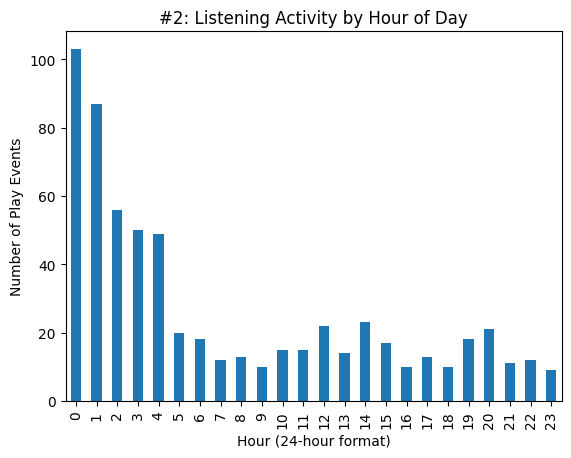

In [7]:
import numpy as np
import pandas as pd
# Import the Listening events as a pandas dataframe.
event_dicts = []

for event in events:
    event_dicts.append({
        "listener_id": event.listener.get_listener_id(),
        "listener_name": event.listener.name,
        "home_city": event.listener.home_city,
        "song_title": event.song.title,
        "artist": event.song.artist,
        "genre": event.song.genre,
        "duration_sec": event.song.duration_sec,
        "timestamp": event.timestamp,
        "seconds_played": int(event.seconds_played)
    })


# Convert the list of dictionaries into a pandas DataFrame
events_df = pd.DataFrame(event_dicts)


# Usinging Groupby find the total listenting time per genre sorted highest to lowest
listeningtime = (events_df.groupby('genre')['seconds_played'].sum()).sort_values(ascending = False)

print('Total Listneing Time per Genre')
listeningtime

# Using Boolean filtering find all listening events for your single most played artist
  # Find the top artist.
top_artist = events_df.groupby('artist')['seconds_played'].sum().idxmax()
print(f"Single most-played artist: {top_artist}")

# fiter to get all events for the artist
top_artist_events = events_df[events_df['artist'] == top_artist]
print(f"Total events found for {top_artist}: {len(top_artist_events)}\n")
# Compute a popularity score using numpy
song_popularity = []
songs_list = events_df['song_title'].unique()

for song in songs_list:
    # Extract seconds_played values for this specific song into a NumPy array
    sec_array = np.array(events_df[events_df['song_title'] == song]['seconds_played'])
    mean_seconds = np.mean(sec_array)
    song_popularity.append({'song_title': song, 'mean_seconds': mean_seconds})

popular_df = pd.DataFrame(song_popularity)

# Vectorized arithmetic: express each average as a % of the highest-scoring song's average
max_mean = popular_df['mean_seconds'].max()
popular_df['popularity_score_pct'] = (popular_df['mean_seconds'] / max_mean) * 100

print("--- Song Popularity Scores (NumPy) ---")
print(popular_df.sort_values(by='popularity_score_pct', ascending=False))
print("\n")


# Chart 1: Total listens by genre
genre_counts = events_df['genre'].value_counts()
genre_counts.plot.bar(
    title="#1: Total Listens by Genre",
    xlabel="Genre",
    ylabel="Number of Listens",
)

# Chart 2: Listening activity by hour of day
times = pd.to_datetime(events_df['timestamp'], 'raise', False, True)
events_df['times'] = times

#hourly_activity = events_df['timestamp'].value_counts().sort_index() # original
hourly_activity = events_df['times'].dt.hour.value_counts().sort_index() # fixed

hourly_activity.plot.bar(
    title="#2: Listening Activity by Hour of Day",
    xlabel="Hour (24-hour format)",
    ylabel="Number of Play Events",
)


# Using pivot reshape the events df
events_df['day'] = events_df['times'].dt.day # added to make it work
pivot_subset = events_df.groupby(['day', 'genre'])['seconds_played'].sum().reset_index() #original line

events_pivot = pivot_subset.pivot(
    index='day',
    columns='genre',
    values='seconds_played'
).fillna(0) # Fill missing combinations with 0 seconds

print("--- Pivot Table: Total Seconds Played by Day and Genre ---")
print(events_pivot.head())



#Part 4) The Case File

Contributions:
*    Fixed certain tricky code to make it work and finished up the project. Wrote the case file.
*    Wrote the main body of code.
*    Wrote Part 3.
*    Started the project by finding Colab and creating a notebook. Wrote part 1

Three specific findings:


*   Music is mostly listened to in the early hours of the day.
*   Nightjar is the single most played artist.
*   Dust and Static is the highest-scored song in terms of popularity.

